## **Shallow water equations**

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
#IMPORT LIBRARIES
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc
import pandas as pd

from the_well.data import WellDataset
from the_well.utils.download import well_download

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# Importing modules from src
from src.datamanager import ROMDataManager, DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import evaluate_model, evaluate_reconstruction_metrics, plot_training_curves

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks_final/SWE
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

In [3]:
# ONLY RUN THIS ONCE TO DOWNLOAD THE DATASET
well_download(base_path="", dataset="planetswe", split="train", first_only=True)

# LOAD THE DATASET
data_folder = "datasets"
dataset = WellDataset(
    well_base_path = data_folder,
    well_dataset_name = "planetswe",
    well_split_name = "train",
    n_steps_input = 1008,
    n_steps_output = 0,
    use_normalization = False,
)
#I've downloaded 0 and 1, you can change this to load the other ones
dataset = dataset[0] 

# BUILD SNAPSHOTS MATRICES

theta = dataset["space_grid"][:,:,0]    # theta: colatitude angle (radians) at each grid point, shape (Lx, Ly)
phi = dataset["space_grid"][:,:,1]      # phi: longitude angle (radians) at each grid point, shape (Lx, Ly)

print("theta shape:\t", theta.shape)
print("phi shape:\t", phi.shape)

ntimes, Lx, Ly, _ = dataset['input_fields'].shape   # ntimes: number of time steps, Lx: number of grid points in x (colatitude), Ly: number of grid points in y (longitude)
nheight = nvelocity = Lx * Ly                       # total number of spatial grid points (flattened)

print("ntimes:\t\t", ntimes)    
print("Lx:\t\t", Lx)            
print("Ly:\t\t", Ly)            
print("nheight:\t", nheight)
print("nvelocity:\t", nvelocity)

H = dataset["input_fields"][:,:,:,0].reshape(ntimes, nheight)           # H: snapshot matrix of height deviation h(x,t), shape (ntimes, nheight)
Utheta = dataset["input_fields"][:,:,:,1].reshape(ntimes, nvelocity)    # Utheta: snapshot matrix of velocity component along colatitude, shape (ntimes, nvelocity)
Uphi = dataset["input_fields"][:,:,:,2].reshape(ntimes, nvelocity)      # Uphi: snapshot matrix of velocity component along longitude, shape (ntimes, nvelocity)

print("H shape:\t", H.shape)
print("Utheta shape:\t", Utheta.shape)
print("Uphi shape:\t", Uphi.shape)

# DELETE DATASET TO FREE UP MEMORY

del dataset

** Resuming transfer from byte position 431
  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed
100    197 100    197   0      0    304      0                              0
** Resuming transfer from byte position 1585479216
  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed
  0      0   0      0   0      0      0      0                              0

100    197 100    197   0      0    286      0                              0


theta shape:	 torch.Size([256, 512])
phi shape:	 torch.Size([256, 512])
ntimes:		 1008
Lx:		 256
Ly:		 512
nheight:	 131072
nvelocity:	 131072
H shape:	 torch.Size([1008, 131072])
Utheta shape:	 torch.Size([1008, 131072])
Uphi shape:	 torch.Size([1008, 131072])


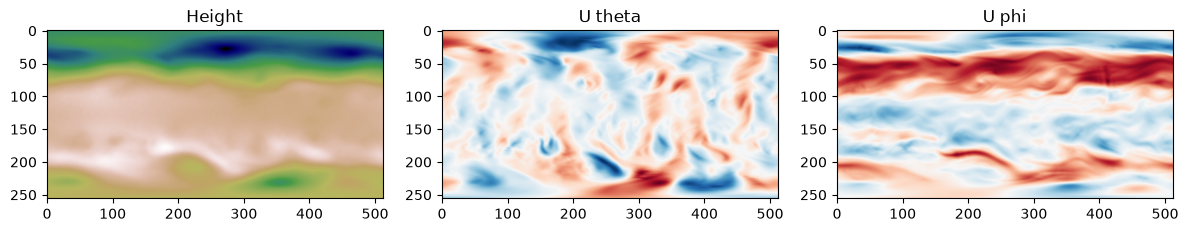

In [4]:
# Define a function to plot the state of the system at a given time step
def plot_state(u, cmap = "RdBu_r"):
    fig = plt.imshow(u.reshape(Lx, Ly), cmap = cmap)

plot_height = lambda u: plot_state(u, cmap = "gist_earth")
plot_velocity = lambda u: plot_state(u, cmap = "RdBu_r")

# Plot the state of the system at the first time step
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plot_height(H[0])
plt.title("Height")
plt.subplot(1, 3, 2)
plot_velocity(Utheta[0])
plt.title("U theta")
plt.subplot(1, 3, 3)        
plot_velocity(Uphi[0])
plt.title("U phi")
plt.tight_layout()
plt.show()

In [5]:
# EXTRACT SENSORS DATA 

# We randomly select 10 sensors on the grid and extract their time series data from the height field H. 
np.random.seed(42)  # For reproducibility
nsensors = 10
sensors_coordinates = np.vstack((np.random.choice(Lx, size = nsensors, replace = True), np.random.choice(Ly, size = nsensors, replace = True))).T
sensors_data = H.reshape(ntimes, Lx, Ly)[:,sensors_coordinates[:,0], sensors_coordinates[:,1]]
print("Sensors coordinates:\n", sensors_coordinates)
print("Sensors data shape:\t", sensors_data.shape)

# BROKEN SENSORS SIMULATION
# short broken : random Bernoulli drops
# long broken  : contiguous outage interval

short_broken = 4   # number of sensors with random drops
long_broken  = 4   # number of sensors with a contiguous outage

# Assign which sensors are broken (first short_broken sensors → random drops,
# next long_broken sensors → long outage)
idx_short_broken_s = np.arange(0, short_broken)
idx_long_broken_s  = np.arange(short_broken, short_broken + long_broken)

# Work on a float copy so NaN can be written
sensors_data = sensors_data.float()

# SHORT BROKEN: Bernoulli mask with probability p_short_broken
p_short_broken = 0.2
for local_idx in idx_short_broken_s:
    broken_mask = torch.rand(sensors_data[:, local_idx].shape) < p_short_broken
    print(f"Short broken sensor {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"{broken_mask.sum().item()} of {ntimes} steps masked")
    sensors_data[:, local_idx][broken_mask] = float('nan')

# LONG BROKEN: contiguous interval
for local_idx in idx_long_broken_s:
    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30:                          # ensure a minimum outage length
        t_end = min(t_start + 38, ntimes - 1)
    print(f"Long broken sensor  {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"steps {t_start} to {t_end} masked")
    sensors_data[t_start:t_end + 1, local_idx] = float('nan')

Sensors coordinates:
 [[102 466]
 [179 214]
 [ 92 330]
 [ 14 458]
 [106  87]
 [ 71 372]
 [188  99]
 [ 20 359]
 [102 151]
 [121 130]]
Sensors data shape:	 torch.Size([1008, 10])
Short broken sensor 0 (coord [102 466]): 200 of 1008 steps masked
Short broken sensor 1 (coord [179 214]): 199 of 1008 steps masked
Short broken sensor 2 (coord [ 92 330]): 204 of 1008 steps masked
Short broken sensor 3 (coord [ 14 458]): 211 of 1008 steps masked
Long broken sensor  4 (coord [106  87]): steps 308 to 661 masked
Long broken sensor  5 (coord [ 71 372]): steps 343 to 769 masked
Long broken sensor  6 (coord [188  99]): steps 413 to 491 masked
Long broken sensor  7 (coord [ 20 359]): steps 385 to 805 masked


In [6]:
from helpers import plot_data_availability
#plot_data_availability(sensors_data, "Sensor data availability", sensor_labels=np.arange(nsensors))
from helpers import ROM_data_preprocessing, eval_all
sensors_data, H, Utheta, Uphi = ROM_data_preprocessing(sensors_data, H, Utheta, Uphi)


Sensors data shape:	 (16, 126, 10)
H shape:		 (16, 126, 131072)
Utheta shape:		 (16, 126, 131072)
Uphi shape:		 (16, 126, 131072)


In [7]:
ERRORS = []

# DataManager
LAGS = 100

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS = 100

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 80           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 1               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]    # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## (T.0.A) Always available sensor

In [8]:
always_available_sensors = np.arange(8,10)
print("Always available sensors:\t", always_available_sensors) 
sensors_data_av = sensors_data[:, :, always_available_sensors]
print("Sensors data shape:\t", sensors_data_av.shape)

Always available sensors:	 [8 9]
Sensors data shape:	 (16, 126, 2)


In [9]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data_av)
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare()

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)




Data shapes after preparation:
Train:	 torch.Size([1512, 100, 2]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 100, 2]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 100, 2]) -> torch.Size([252, 300])

Input shape for the model: 2
Output shape for the model: 300


In [10]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T0A.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_path.exists():
    print("Training mSHRED model...")
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )
    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T0A")

del model_args, model_path, mshred


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        4316.970661        0.182862       44.889888        0.026376
val          5086.548427        0.202357       49.630699        0.032198
test         4720.928520        0.193871       47.177551        0.031896

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train          14.576781        0.581507        2.897931        0.042868
val            18.771601        0.669947        3.305484        0.051964
test           17.847729        0.626342        3.203861        0.051900

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train          19.125788        0.33482

## (T.0.B) Always available sensor (LSTM)


In [11]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="lstm", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, num_layers=ENCODER_DEPTH,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T0B.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T0B")

del model_args, model_path, mshred
del model_exists
del train_dataset, val_dataset, test_dataset


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        5262.877059        0.204389       50.341122        0.029579
val          5445.626575        0.209186       51.572555        0.033458
test         5146.577583        0.202168       48.874337        0.033043

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train          18.339716        0.654821        3.239611        0.047922
val            20.173951        0.696655        3.438779        0.054059
test           19.097753        0.652608        3.313143        0.053670

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train          23.690455        0.37477

## (T.1.A): Median imputer

In [12]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, imputer="median")
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare()

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)




Data shapes after preparation:
Train:	 torch.Size([1512, 100, 10]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 100, 10]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 100, 10]) -> torch.Size([252, 300])

Input shape for the model: 10
Output shape for the model: 300


In [13]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T1A.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T1A")

del model_args, model_path, mshred
del model_exists


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        2007.188228        0.118535       29.737917        0.017473
val          3202.250951        0.160024       39.395533        0.025558
test         3383.371505        0.164778       40.101499        0.027112

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           9.271025        0.449926        2.261718        0.033457
val            14.900916        0.595768        2.952105        0.046408
test           14.578146        0.568975        2.926951        0.047414

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train          10.052429        0.23234

## (T.1.B): Mean imputer

In [14]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, imputer="mean")
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare()

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)




Data shapes after preparation:
Train:	 torch.Size([1512, 100, 10]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 100, 10]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 100, 10]) -> torch.Size([252, 300])

Input shape for the model: 10
Output shape for the model: 300


In [15]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T1B.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T1B")

del model_args, model_path, mshred
del model_exists
del train_dataset, val_dataset, test_dataset


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        2249.373759        0.126767       31.728612        0.018643
val          3242.423502        0.160166       40.169102        0.026060
test         3840.905928        0.176532       42.971197        0.029052

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           9.683374        0.463400        2.319488        0.034311
val            14.072504        0.579316        2.857835        0.044926
test           15.438232        0.585216        3.016397        0.048863

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train          10.933676        0.24560

## (T.1.C): Last value imputer

In [16]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, imputer="last_value")
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare()

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)




Data shapes after preparation:
Train:	 torch.Size([1512, 100, 10]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 100, 10]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 100, 10]) -> torch.Size([252, 300])

Input shape for the model: 10
Output shape for the model: 300


In [17]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T1C.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T1C")

del model_args, model_path, mshred
del model_exists
del train_dataset, val_dataset, test_dataset


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        4121.636441        0.175110       42.783079        0.025138
val          4067.419120        0.175713       43.805228        0.028419
test         5401.765327        0.208041       51.346122        0.034714

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train          14.251797        0.557806        2.821228        0.041733
val            16.737907        0.610563        3.077554        0.048380
test           19.280744        0.655268        3.373074        0.054641

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train          19.775194        0.32890

## (T.2.A) GRUD

In [18]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data)
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(masking_type="grud")

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[-1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)




Data shapes after preparation:
Train:	 torch.Size([1512, 4, 100, 10]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 4, 100, 10]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 4, 100, 10]) -> torch.Size([252, 300])

Input shape for the model: 10
Output shape for the model: 300


In [19]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T2A.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T2A")

del model_args, model_path, mshred
del model_exists


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        1687.510732        0.109061       28.171697        0.016553
val          3129.937127        0.155188       38.887178        0.025228
test         1780.079827        0.117859       30.371344        0.020533

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           8.836796        0.442484        2.195267        0.032474
val            13.881258        0.574884        2.814391        0.044243
test            9.315520        0.451427        2.311432        0.037443

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           9.029168        0.21999

## (T.2.B): Attn-GRUD

In [20]:
# Attn-GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T2B.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T2B")

del model_args, model_path, mshred
del model_exists
del train_dataset, val_dataset, test_dataset


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        1962.005874        0.119224       30.616433        0.017990
val          3328.200168        0.158512       39.417586        0.025573
test         2409.856339        0.136986       34.434493        0.023280

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           9.630907        0.463705        2.305560        0.034105
val            13.963009        0.575651        2.805436        0.044103
test           11.019377        0.483651        2.503153        0.040549

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           9.976592        0.23415

## (T.3.A): Masking

In [21]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data)
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)




Data shapes after preparation:
Train:	 torch.Size([1512, 100, 10]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 100, 10]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 100, 10]) -> torch.Size([252, 300])

Input shape for the model: 10
Output shape for the model: 300


In [22]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3A.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T3A")

del model_args, model_path, mshred
del model_exists


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        1681.104164        0.111390       28.373242        0.016672
val          3028.842457        0.154982       38.524824        0.024993
test         2306.588004        0.137353       34.541891        0.023353

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           8.164092        0.428551        2.141943        0.031685
val            12.888939        0.556051        2.750429        0.043238
test           10.918230        0.489083        2.543584        0.041204

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           8.794050        0.22076

## (T.3.B): Masking x2 channels

In [23]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3B.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T3B")

del model_args, model_path, mshred
del model_exists


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        1235.328976        0.092190       23.615509        0.013876
val          2293.117835        0.133202       33.805261        0.021931
test         1800.667790        0.120388       29.730068        0.020100

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           6.139206        0.365988        1.824801        0.026994
val            10.441807        0.497436        2.471067        0.038846
test            8.881395        0.441353        2.258867        0.036592

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           5.958740        0.17829

## (T.3.C): Masking hidden space

In [24]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3C.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T3C")

del model_args, model_path, mshred
del model_exists


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        1688.507730        0.109404       27.794069        0.016331
val          2502.029227        0.140178       34.947792        0.022673
test         3015.014394        0.157175       38.918593        0.026312

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           7.797158        0.414303        2.072395        0.030656
val            11.817642        0.531466        2.631439        0.041367
test           12.871980        0.532417        2.758415        0.044684

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           8.498924        0.21487

## (T.3.D): Masking MHSA

In [25]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3D.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T3D")

del model_args, model_path, mshred
del model_exists


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        1666.993816        0.108620       27.713438        0.016284
val          3067.641814        0.155499       38.816309        0.025182
test         2507.452250        0.143396       35.859285        0.024244

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           7.741454        0.413586        2.073310        0.030670
val            12.736169        0.553382        2.742088        0.043107
test           11.469142        0.502668        2.610364        0.042285

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           8.436931        0.21354

## (T.3.E): Masking x2 channels + MHSA

In [26]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3E.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T3E")

del model_args, model_path, mshred
del model_exists


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        1426.082944        0.099317       25.286086        0.014858
val          2890.962208        0.149285       36.974774        0.023988
test         1858.402247        0.120009       30.074351        0.020333

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           7.090518        0.396492        1.972218        0.029174
val            12.123996        0.537553        2.642035        0.041534
test            8.843820        0.437724        2.269025        0.036756

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           7.005976        0.19357

## (T.3.F): Masking MHSA learned

In [27]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3F.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T3F")

del model_args, model_path, mshred
del model_exists


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        1527.273369        0.103372       26.413894        0.015520
val          3071.142862        0.154797       38.432493        0.024933
test         2253.620546        0.135989       34.102215        0.023056

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           7.434595        0.403822        2.020342        0.029886
val            12.501052        0.545690        2.700811        0.042458
test           11.131363        0.494435        2.562164        0.041505

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           7.400845        0.19887

## (T.3.G): Masking x2 channels + MHSA learned

In [28]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3G.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi, model_name="T3G")

del model_args, model_path, mshred
del model_exists
del train_dataset, val_dataset, test_dataset


Loading pre-trained mSHRED model...

Surface elevation
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train        1636.250517        0.105674       26.755083        0.015721
val          3081.632207        0.149196       36.772678        0.023857
test         2329.618150        0.137507       34.219453        0.023135

Velocity theta
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           7.473233        0.404479        2.013912        0.029791
val            11.542110        0.524382        2.573605        0.040458
test           10.879324        0.485391        2.525357        0.040908

Velocity phi
split                MSE             MRE             MAE            NMAE
------------------------------------------------------------------------
train           7.794596        0.20422

## Results

In [29]:
import json
from pathlib import Path

metrics_path = Path("reconstruction_metrics_all_models.json")
with metrics_path.open("r", encoding="utf-8") as json_file:
    metrics_by_model = json.load(json_file)

aggregate_field = "Unify all"
sorted_models = sorted(
    (
        (model_name, model_metrics["test"][aggregate_field]["nmae"])
        for model_name, model_metrics in metrics_by_model.items()
        if model_metrics is not None
    ),
    key=lambda item: item[1],
)

print(f"Models sorted by test NMAE - {aggregate_field}:")
for model_name, test_nmae in sorted_models:
    print(f"{model_name}: {test_nmae:.6f}")


Models sorted by test NMAE - Unify all:
T3B: 0.028903
T3E: 0.029055
T2A: 0.029446
T2B: 0.032200
T3G: 0.032865
T3F: 0.033074
T3A: 0.033297
T3D: 0.034390
T3C: 0.036752
T1A: 0.038807
T1B: 0.040511
T0A: 0.043749
T0B: 0.045286
T1C: 0.047436
